# Notebook da aula 06 - Imputação e Normalização de Dados

Nessa aula utilizamos a base de dados já usada na atividade prática, o imoveis_sao_paulo.csv, já que ela possuía alguns problemas, como lacunas em algumas colunas, variáveis medidas em unidades diferentes e uma distribuição com cauda longa

### **1 - preparação da base**

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.preprocessing import (
    MinMaxScaler,
    PowerTransformer,
    RobustScaler,
    StandardScaler,
)

sns.set_theme(style="whitegrid", palette="colorblind")

In [3]:
# Novos nomes para as colunas com espaços e símbolos
column_names = {
    "parking spaces": "parking_spaces",
    "hoa (R$)": "hoa",
    "rent amount (R$)": "rent_amount",
    "property tax (R$)": "property_tax",
    "total (R$)": "total",
}

In [4]:
# Carrega a base, remove duplicatas e identifica o tipo de imóvel
imoveis = (
    pd.read_csv('C:/Users/13044280443/Ciência de Dados - UF/unidade_02/aula_06/imoveis_sao_paulo.csv')
    .rename(columns=column_names)
    .drop_duplicates()
    .reset_index(drop=True)
    .assign(
        property_type=lambda df: np.where(
            df["floor"].isna(),
            "casa",
            "apartamento",
        )
    )
)

#### 1.1 - Problemas iniciais encontrados previamente:

Como mencionado no notebook disponibilizado pelo professor, é necessário saber quais problemas ocorrem em uma coluna primeiro para assim cosneguirmos tratá-lo. No diagnóstico rápido feito na seção, foram observados três problemas que serão tratados  no decorrer do notebook:
 * **Valores ausentes,** calculado por: 


In [ ]:
missing = (
    imoveis[["hoa", "parking_spaces", "floor"]]
    .isna()
    .mean()
    .mul(100)
)

Aqui, o missing calcula a porcentagem de valores ausentes nos atributos hoa, parking_spaces e floor.

* **Escalas incompatíveis**

In [8]:
scales = (
    imoveis[["rooms", "area", "rent_amount"]]
    .median()
)

O scales nos dá a mediana de atributos com cada unidade original.

* **Cauda Longa** 

In [9]:
limit = imoveis["rent_amount"].quantile(.99)

Esse percentil 99 recorta exatamente a "cauda longa", o desvio na distibuição, mas esse recorte é apenas para vizualização, nenhum dado é removido.

##### Gráficos com um resumo dos problemas falandos anteriormente

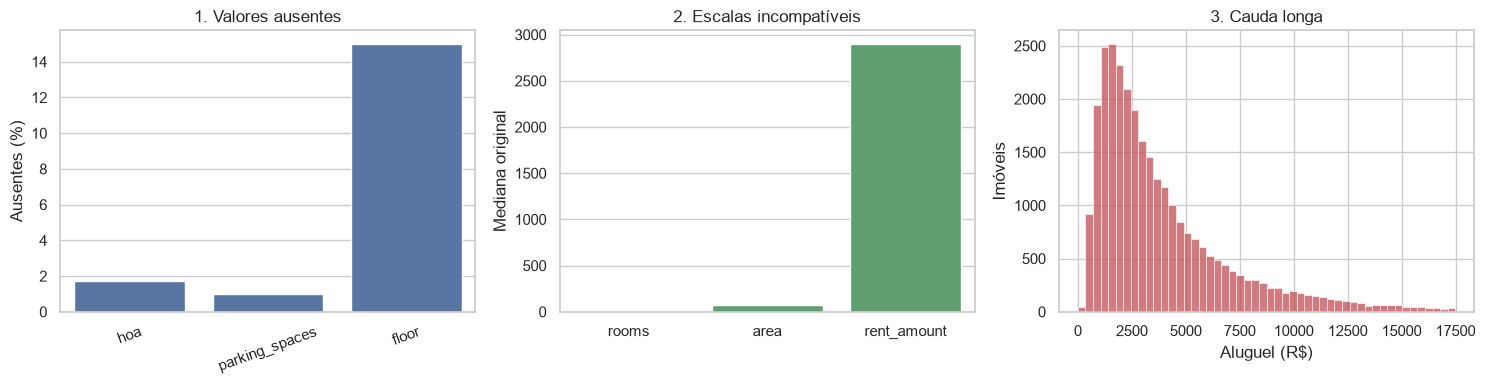

In [10]:
# Figura-resumo com os três problemas da aula
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.barplot(
    x=missing.index,
    y=missing.values,
    ax=axes[0],
    color="#4C72B0",
)
axes[0].set(
    title="1. Valores ausentes",
    ylabel="Ausentes (%)",
    xlabel="",
)
axes[0].tick_params(axis="x", rotation=20)

sns.barplot(
    x=scales.index,
    y=scales.values,
    ax=axes[1],
    color="#55A868",
)
axes[1].set(
    title="2. Escalas incompatíveis",
    ylabel="Mediana original",
    xlabel="",
)

sns.histplot(
    imoveis["rent_amount"],
    bins=50,
    binrange=(0, limit),
    ax=axes[2],
    color="#C44E52",
)
axes[2].set(
    title="3. Cauda longa",
    xlabel="Aluguel (R$)",
    ylabel="Imóveis",
)

plt.tight_layout()
plt.show()

A partir dos gráficos é perceptível que em:

* **Valores ausentes:** A diferença de valores ausentes entre floor e as outras duas colunas é um pouco grande, o que pode nos levar a formulação da hipótes de que essa discrepância ocorra por alguma causa própria;
* **Escalas incompatíveis:** Com as grandezas de diferentes ordens em cada atributo, quando comparamos as colunas rooms e area com rent_amoount, notamos que essa última domina a gráfico, pois sua unidade numérica é maior, tornando as outras quase invisíveis, o que é ruim para treinamento futuro de alum modelo de machine learning;
* **Cauda longa:** O terceiro gráfico evidencia que os preços dos imóveis não seguem uma distribuição normal, mesmo tendo uma grande maioria de imoveis com preços mais baixos, há uma pequena quantidade com preços mais altos, o que causa esse desvio para a direita.

### **2 - Ausência estrutural**

Algo que ocorre com essa base de dados e já foi percebida anteriormente é  a falta de dados, principalmente na coluna floor, na análise incial é imprescindível que analisemos mais a fundo se esses dados faltantes foram algum erro mesmo ou tem algum motivo para estarem assim antes de tentar preencher essas lacunas logo. A hipótese inicial é de que a ausência de andares seria pelo fato de haver casa cadastradas nessa base de dados. Ao ver a quantidade de imóveis sem andar e quantos são o tipo "casa" percebemos que é exatamente o que acontece, pois nesse tipo de imóvel não há floor e total_floors. 

In [11]:
# Número de imóveis e proporção sem andar, por tipo
(
    imoveis
    .groupby("property_type")
    .agg(
        imoveis=("property_type", "size"),
        proporcao_sem_andar=(
            "floor",
            lambda x: (
                x
                .isna()
                .mean()
            ),
        ),
    )
)

,imoveis,proporcao_sem_andar
property_type,,
apartamento,25024,0.0
casa,4415,1.0


Nesse caso, apenas preencher as lacunas, sem exploração prévia  pode retornar alguma informação distorcida da realidade, o mais interessante é agrupar e separar essas porções cujos dados estão faltantes por motivo plausível e imputar valores numéricos apenas em informaç~´oes onde realmente houve algum erro de preenchimento, como aluguel não informado ou número de vagas não registrado.

### **3 - Imputação: o impacto das alternativas**

Para substituir valores ausente existem diversas formas, como usar uma medida de posição da própria coluna, métodos multivariados, etc. Mas, ná prática, há uma dificuldade em fazer isso,  não conseguimos calcular diretamento o erro dessa imputação, pois não sabemos qual o valor real daquela lacuna. Para amenizxar esse problema usamos a estratégia de simulação de alguns problemas parecidos:
* Utilizamos alguns registros completos;
* Apagamos alguns valores desse registros;
* Imputamos e em seguida comparamos com os valores originais

In [12]:
# Função de apagamento e base-gabarito
rng = np.random.default_rng(42)

def erase_at_random(values, share):
    return values.mask(rng.random(len(values)) < share)

imoveis_true = (
    imoveis
    .dropna(subset=["hoa", "parking_spaces"])
    .reset_index(drop=True)
)

Essa primeira função é responsável por apagar alguns valores da base de dados

In [13]:
# Apaga valores em três colunas de tipos diferentes
imoveis_missing = (
    imoveis_true
    .assign(
        rooms=lambda df: erase_at_random(df["rooms"], .10),
        rent_amount=lambda df: erase_at_random(df["rent_amount"], .15),
        furniture=lambda df: erase_at_random(df["furniture"], .08),
    )
)

Essa segunda função cria uma base de dados onde valores de três variáveis estão faltantes, apagando 10% de room, 15% de rent_amount e 8% de furniture

In [ ]:
# Quantidade e proporção de valores apagados por coluna
# Apenas conferência de quantos valores foram apagados
(
    imoveis_missing[["rooms", "rent_amount", "furniture"]]
    .isna()
    .sum()
    .to_frame("ausentes")
    .assign(
        proporcao=lambda x: (
            x.ausentes / len(imoveis_missing)
        ).round(3)
    )
)

,ausentes,proporcao
rooms,2783,0.097
rent_amount,4308,0.150
furniture,2254,0.079
